#CVPR 2025, Lab class #1

## Estimating homography
In this example, we will estimate homographies from a set of checkerboard images. **Estimating homographies is the first step of the Zhang's calibration method**.

### Libraries
Besides [Numpy](https://numpy.org/) and the [Ployly library](https://github.com/plotly/plotly.py), we will need [OpenCV](https://opencv.org/).

In [223]:
import plotly.express as px

import os

import numpy as np

import cv2 # OpenCV
print (cv2.__version__)

4.12.0


Make sure to check the docs for the **your version** of OpenCV, for example, if the installed version is 4.12.0, then the documentation can be found here: https://docs.opencv.org/4.12.0/

### Loading and displaying images using OpenCV
Let the images be located in the `images/` folder. Notice that it may be a folder in your GDrive or even **a shortcut to a folder that is shared with you**.

In [224]:
from google.colab import drive
from google.colab.patches import cv2_imshow
drive.mount('/content/drive/', force_remount=True)
GDrivePath = '/content/drive/MyDrive/'

Mounted at /content/drive/


In [225]:
folderpath = GDrivePath + '/CVPR_project/images/'
filepath = folderpath+'rubik.jpg'
image = cv2.imread(filepath)


Let's check the type. If for some reason the image is not loaded, no error is raised, but the type will be `NoneType`.

In [226]:
type(image)

numpy.ndarray

Let's check the data type, which should be 8-bit unsigned integer.

In [227]:
print(image.dtype)

uint8


We can check its size by inspecting its `shape` property (despite the appearance, it is a 3-channel image):

In [228]:
image.shape

(1000, 1000, 3)

Visualize the image. Notice that, **if using Colab, the following will raise an error** (commented for convenience).

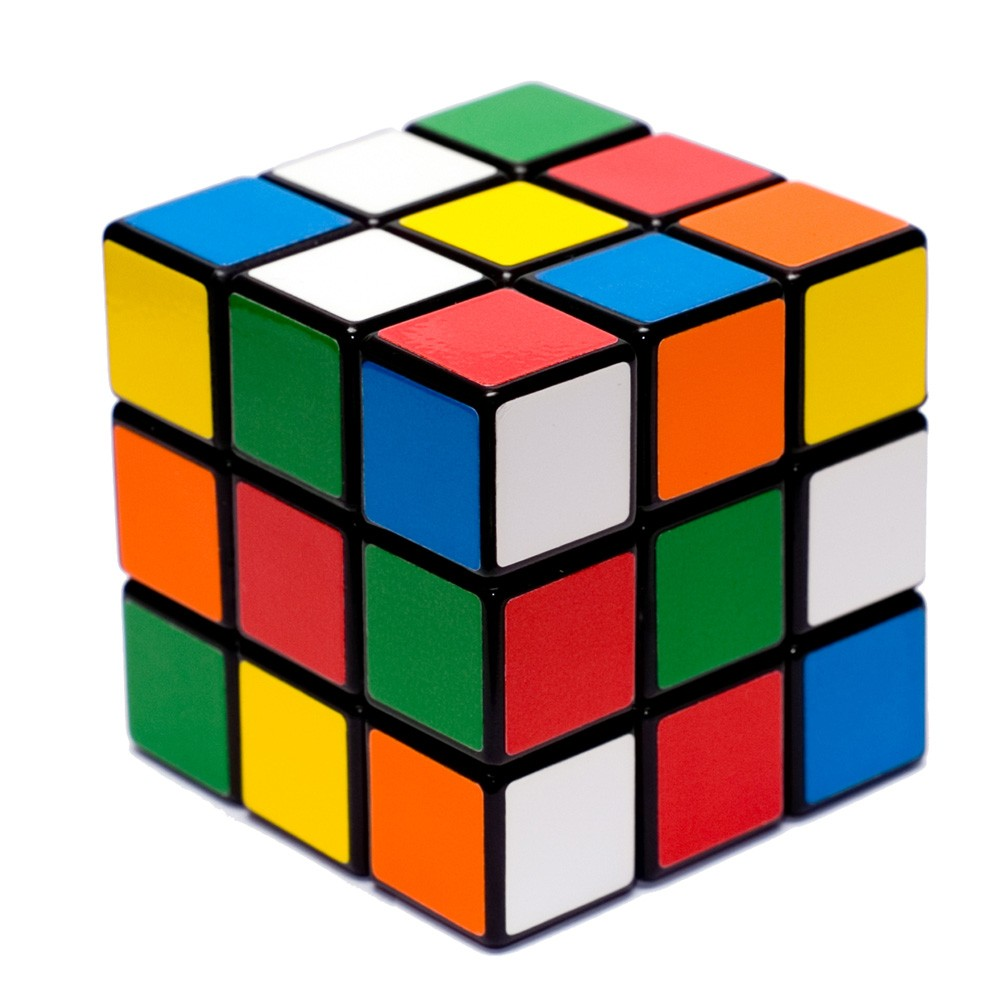

In [229]:
cv2_imshow(image) # <--- raises an error if using Colab (try it and read carefully the error message)
#cv2.waitKey(0)
#cv2.destroyAllWindows()

You may use a workaround suggested in the error message, or simply use pylot:

In [230]:
fig = px.imshow(image)
fig.show()

OpenCV stores the channels in the **BGR order**, while pyplot expects the images in the most common RGB order. To display the right colors you need to convert the images before:

In [231]:
fig = px.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
fig.show()

In [232]:

folderpath = GDrivePath + '/CVPR_project/images_and_poses_for_project_assignment/'

filepath = folderpath+ 'rgb_0.png'
image_BGR= cv2.imread(filepath)

image=cv2.cvtColor(image_BGR, cv2.COLOR_BGR2RGB)

fig = px.imshow(image)
fig.show()

Load a checkerboard image.

By setting the size of the figure, we can adjust the size of the displayed image.

In [233]:
figure_width=1200
figure_height=1200
fig = px.imshow(image,width=figure_width,height=figure_height, color_continuous_scale='gray')
fig.show()


### Detect checkerboard corners
To estimate homographies between the checkerboard plane and the image plane, we need *a set of correspondeces (at least four) between 3D points lying on the checkerboard pattern and 2D points in the image*. To detect the corners, we may emply the function `findChessboardCorners` provided by OpenCV. We must specify the size (number of corners in each side).



In [234]:
grid_size = (8, 11) #the number of corners on each side

return_value, corners = cv2.findChessboardCorners(image, patternSize=grid_size)
return_value # must be True, otherwise the corners were not found

True

Let's check the coordinates of the detected corners.

In [235]:
print(corners.dtype)
#print(corners)
print(corners.shape)

float32
(88, 1, 2)


We may reshape the array to be two dimensional:

In [236]:
corners=corners.reshape((88,2)).copy()
print(corners)
print(corners.shape)

[[430.4773  524.2329 ]
 [432.13327 485.06973]
 [433.72046 445.7927 ]
 [435.47113 406.87054]
 [437.08923 367.96738]
 [438.47504 329.51947]
 [439.87872 290.7805 ]
 [441.44733 251.9149 ]
 [469.5736  525.40967]
 [471.26605 486.08234]
 [472.98257 447.22058]
 [474.43393 408.33398]
 [475.97137 369.53833]
 [477.48935 331.09787]
 [478.7984  292.33218]
 [480.23004 253.5727 ]
 [508.4236  526.723  ]
 [509.9962  487.5734 ]
 [511.56668 448.59366]
 [513.26306 409.4479 ]
 [514.5795  370.87402]
 [516.1736  332.57968]
 [517.4816  293.79205]
 [518.8405  255.36827]
 [547.4299  527.9524 ]
 [548.8896  488.83725]
 [550.47815 449.93796]
 [551.8308  411.1975 ]
 [553.5053  372.5197 ]
 [554.84283 334.09885]
 [556.3447  295.37766]
 [557.53424 256.86896]
 [585.9938  529.35693]
 [587.5876  490.25894]
 [588.951   451.3821 ]
 [590.47723 412.5332 ]
 [591.8039  373.66428]
 [593.5514  335.50806]
 [594.70325 296.8765 ]
 [596.1752  258.37146]
 [624.8884  530.7123 ]
 [626.4435  491.663  ]
 [627.607   452.85077]
 [629.257  

Notice that the coordinates are represented as `float32`. The output of `findChessboardCorners` is however approximate, and may be refined to sub-pixel precision using `cornerSubPix()` (which requires a **single channel input image**).

In [237]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) #here again, the channel order is irrelevant
gray.shape
fig = px.imshow(gray)
fig.show()

Output hidden; open in https://colab.research.google.com to view.

In [238]:
criteria = (cv2.TERM_CRITERIA_MAX_ITER | cv2.TERM_CRITERIA_EPS, 100, 0.001) # tuple for specifying the termination criteria of the iterative refinement procedure cornerSubPix()
cv2.cornerSubPix(gray,corners,(5,5),(-1,-1),criteria)
corners[-1,:] # last row of corners after refinement. Compare the refined coordinates to the original ones in the output above

array([827.47015, 266.57092], dtype=float32)

We may use [`drawChessboardCorners()`](https://docs.opencv.org/4.8.0/d9/d0c/group__calib3d.html#ga6a10b0bb120c4907e5eabbcd22319022) for visualizing the detected corners (notice that `image` is an output of the function as well).

In [239]:
image_copy = image.copy()
cv2.drawChessboardCorners(image_copy, grid_size, corners, return_value)
fig = px.imshow(image_copy,width=figure_width,height=figure_height)
fig.show()

### Detection for multiple images

We now may repeat the same process for all of the images in the `images/` folder.

We'll use `os.listdir` to find all the appropriate pictures.

In [240]:
images_path = [os.path.join(folderpath, imagename) for imagename in os.listdir(folderpath) if imagename.endswith(".png")]
images_path.sort()
#images_path

In [241]:
import re
import os


images_path.sort(key=lambda f: int(re.sub(r'\D', '', os.path.basename(f))))

drawn_images = []

for p in images_path:
    print(p)
    im = cv2.imread(p)
    img = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)

    return_value, corners_ = cv2.findChessboardCorners(img, patternSize=grid_size, corners=None)

    # drawChessboardCorners modifies the image in-place and returns it
    img_drawn = cv2.drawChessboardCorners(img, grid_size, corners_, return_value)
    drawn_images.append(img_drawn)

    if not return_value:
        print(f"Pattern not found for image {p}")


/content/drive/MyDrive//CVPR_project/images_and_poses_for_project_assignment/rgb_0.png
/content/drive/MyDrive//CVPR_project/images_and_poses_for_project_assignment/rgb_1.png
/content/drive/MyDrive//CVPR_project/images_and_poses_for_project_assignment/rgb_2.png
/content/drive/MyDrive//CVPR_project/images_and_poses_for_project_assignment/rgb_3.png
/content/drive/MyDrive//CVPR_project/images_and_poses_for_project_assignment/rgb_4.png
/content/drive/MyDrive//CVPR_project/images_and_poses_for_project_assignment/rgb_5.png
/content/drive/MyDrive//CVPR_project/images_and_poses_for_project_assignment/rgb_6.png
/content/drive/MyDrive//CVPR_project/images_and_poses_for_project_assignment/rgb_7.png
/content/drive/MyDrive//CVPR_project/images_and_poses_for_project_assignment/rgb_8.png
/content/drive/MyDrive//CVPR_project/images_and_poses_for_project_assignment/rgb_9.png
/content/drive/MyDrive//CVPR_project/images_and_poses_for_project_assignment/rgb_10.png
/content/drive/MyDrive//CVPR_project/image

In [242]:
import sys
sys.path.append(GDrivePath +'CVPR_project/')
from utils import create_compound_image
compound_image=create_compound_image(rows=4,cols=5,limages=drawn_images)

fig = px.imshow(compound_image,width=figure_width,height=figure_height)
fig.show()

Output hidden; open in https://colab.research.google.com to view.

### Visualizing correspondences

Since we know that each grid has a height and width of 11 mm, we can visualize the correspondences between detected points in the image.

We know that the coordinates of the corners are stored in the array `corners`, which has a shape of $88 \times 1 \times 2$: for each corner coordinate, we can display the 3D coordinates of the corners in the real world using the plane imposed by the checkerboard as a reference plane with the origin centered at the first corner in the `corners` array. Note: we don't display the $z$ coordinate as it's 0 for all points, since they lie on the checkerboard.

Note that `corners` contains the coordinates of the corners detected on the selected image only, which in the starter code is the `images/image00.tiff`.

In [243]:
for index, corner in enumerate(corners):
  grid_size_cv2 = tuple(reversed(grid_size))

  u_index, v_index = np.unravel_index(index, grid_size_cv2)
  print(u_index, v_index)

0 0
0 1
0 2
0 3
0 4
0 5
0 6
0 7
1 0
1 1
1 2
1 3
1 4
1 5
1 6
1 7
2 0
2 1
2 2
2 3
2 4
2 5
2 6
2 7
3 0
3 1
3 2
3 3
3 4
3 5
3 6
3 7
4 0
4 1
4 2
4 3
4 4
4 5
4 6
4 7
5 0
5 1
5 2
5 3
5 4
5 5
5 6
5 7
6 0
6 1
6 2
6 3
6 4
6 5
6 6
6 7
7 0
7 1
7 2
7 3
7 4
7 5
7 6
7 7
8 0
8 1
8 2
8 3
8 4
8 5
8 6
8 7
9 0
9 1
9 2
9 3
9 4
9 5
9 6
9 7
10 0
10 1
10 2
10 3
10 4
10 5
10 6
10 7


In [244]:
square_size = 11
another_copy=image.copy()

real_coordinates = np.empty_like(corners)

for index, corner in enumerate(corners):

    u_coord = corner[0] #pxl
    v_coord = corner[1]

    # unravel_index converts an index from linear to 2d
    # example: index 7 of a 3x4 matrix corresponds to position (1, 3) of the matrix (NOTE: 0-based indexing)
    # notice that we revert the grid size as 2d matrices are stored differently in Python and the OpenCV backend
    grid_size_cv2 = tuple(reversed(grid_size))
    u_index, v_index = np.unravel_index(index, grid_size_cv2)

    # the coordinates of the corner w.r.t. the reference corner at position (0,0) of the corners array
    x_mm = (u_index) * square_size
    y_mm = (v_index) * square_size

    # we store them in the real_coordinates array
    real_coordinates[index,:] = [x_mm, y_mm]

    # this superimposes the text to the image - NOTE: it overwrites current image, this is why we work on a copy of img

    cv2.putText(another_copy, text=f"{x_mm};{y_mm}", org=(round(u_coord),round(v_coord)), fontFace=cv2.FONT_HERSHEY_SIMPLEX, fontScale=.4, color=(255,0,0), thickness=1)

fig = px.imshow(another_copy,width=figure_width,height=figure_height)
fig.show()



# Assignment
Given the correspondences, implement the procedure for **estimating the homography**. There is one homography per image, but just consider the selected image, whose corners are stored in `corners`. The procedure is outlined in Lecture 3, page 67 and reported next for convenience.

Consider a plane such that $z=0$. The perspective projection is then

$$
w \left[
\begin{array}{c}
u \\
v \\
1
\end{array}
\right]=P
\left[
\begin{array}{c}
x \\
y \\
0 \\
1
\end{array}
\right]=
\left[
p_1 \; p_2 \; p_3 \; p_4
\right]
\left[
\begin{array}{c}
x \\
y \\
0 \\
1
\end{array}
\right]=
\left[ p_1 \; p_2 \; p_4 \right]
\underbrace{\left[
\begin{array}{c}
x \\
y \\
1
\end{array}
\right]}_{\doteq m}.
$$
Let $H=\left[p_1 \; p_2 \; p_3 \; p_4\right]$ be partitioned row-wise as
$$
H=\left[
\begin{array}{c}
h_1^\top \\
h_2^\top \\
h_3^\top
\end{array}
\right].
$$
Then we get
$$
\left\{
\begin{aligned}
wu &= h_1^\top m \\
wv &= h_2^\top m \\
w &= h_3^\top m
\end{aligned}
\right.
\qquad \qquad \Longrightarrow \qquad \qquad
\left\{
\begin{aligned}
u &= \dfrac{h_1^\top m }{h_3^\top m }\\
v &= \dfrac{h_2^\top m }{h_3^\top m }
\end{aligned}
\right.
\qquad \qquad \Longrightarrow \qquad \qquad
\left\{
\begin{aligned}
h_1^\top m - u h_3^\top m &= 0\\
h_2^\top m - v h_3^\top m &= 0
\end{aligned}
\right.
$$

By transposing we get
$$
\left\{
\begin{aligned}
m^\top h_1 - u m^\top h_3 &= 0\\
m^\top h_2 - v m^\top h_3 &= 0
\end{aligned}
\right.,
$$
and, in matrix form:
$$
\left[
\begin{array}{ccc}
m^\top & 0^\top & -um^\top \\
0^\top & m^\top & -vm^\top
\end{array}
\right]
\left[
\begin{array}{c}
h_1 \\
h_2 \\
h_3
\end{array}
\right]=0.
$$
Hence, each correspondence provides two equations.
Since $H$ has nine entries but is defined up to a scale factor, the actual degrees of freedom are eight. Therefore, at least four correspondences are necessary.
In practice, it is advisable to use many more than four points, obtaining a ``tall'' matrix of size $2N \times 9$. Due to measurement and modeling errors, the matrix will be rank nine, thus a least squares solution can be found by means of Singular Value Decomposition.

In [245]:
# CONSTRUCT A
A_first_point = np.empty((0, 9), dtype=float)

A=A_first_point
corners = corners.reshape(-1, 2) # Reshape corners to (N, 2)
for index, corner in enumerate(corners):
    u, v = corner[0], corner[1]


    grid_size_cv2 = tuple(reversed((grid_size)))
    u_index, v_index = np.unravel_index(index, grid_size_cv2)

    # the coordinates of the corner w.r.t. the reference corner at position (0,0) of the corners array
    x = (u_index) * square_size
    y= (v_index) * square_size
    # we store them in the real_coordinates array
    A_stack= np.array(
      [[x, y, 1, 0, 0, 0, -u * x, -u * y, -u],
      [0, 0, 0, x, y, 1, -v * x, -v * y, -v]
      ], dtype=np.float32)
    A=np.vstack([A, A_stack])
    #print(A)
    # complete appropriately the construction of A


#print(A[0])
print(A.shape)
# SOLVE A*h=0 for h using Singular Value Decomposition (use the function numpy.linalg.svd: https://numpy.org/doc/2.3/reference/generated/numpy.linalg.svd.html)

# RECOVER the matrix H from the solution h


U, S, Vh = np.linalg.svd(A, full_matrices=False)


h = Vh[-1, :]   # last row of Vh (smallest singular value)

H = h.reshape(3, 3)
H=H/H[2,2]
#print("Homography matrix H:")
print(H)


(176, 9)
[[ 3.54336221e+00  1.84149297e-01  4.30707203e+02]
 [ 1.38212272e-01 -3.50238852e+00  5.23783496e+02]
 [ 1.90112731e-05  9.07376559e-05  1.00000000e+00]]


In [246]:
#checking
# Convert to homogeneous
p0 = np.array([0, 0, 1.0])

# Apply the homography


p0_transformed = H@ p0
# Norrnalize
#p0_transformed /= p0_transformed[2]
print( p0_transformed)


[430.70720286 523.78349608   1.        ]


# Homework
Superimpose a rectangle to the checkerboard (the input are the rectangle's width and height and the coordinates of one of the vertices). You should be able to get results such as the following.

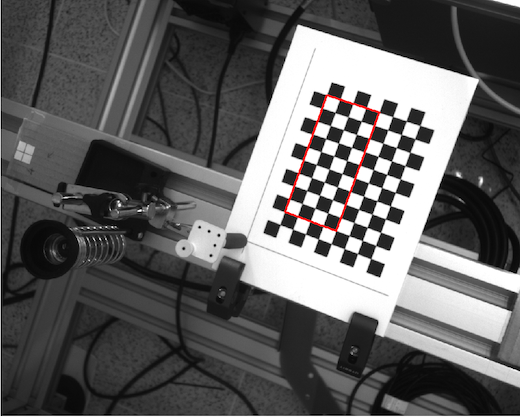


In [247]:
rect_width = 99     # [mm]
rect_height = 44    # [mm]

bottom_left_corner_x = 11   # [mm]
bottom_left_corner_y = 33   # [mm]

# complete (compute the homography and draw the rectangle)

p0 = np.array([bottom_left_corner_x, bottom_left_corner_y, 1.0]) #constructing vector for bottom left corner

p0_transformed = H@ p0
p0_transformed=p0_transformed/p0_transformed[2]


print("Transformed point bottom left corner (x,y ):", p0_transformed)


bottom_right_corner_x = np.array([bottom_left_corner_x+rect_width, bottom_left_corner_y, 1.0])
brct=H@ bottom_right_corner_x
brct=brct/brct[2]
print("Transformed point bottom right corner (x,y ):", brct)

top_left_corner_x = np.array([bottom_left_corner_x, bottom_left_corner_y+rect_height, 1.0])
tlct=H@ top_left_corner_x
tlct=tlct/tlct[2]
print("Transformed point top left corner (x,y ):", tlct)


top_right_corner_x = np.array([bottom_left_corner_x+rect_width, bottom_left_corner_y+rect_height, 1.0])
trct=H@ top_right_corner_x
trct=trct/trct[2]
print("Transformed point top right corner (x,y ):", trct)

image=cv2.cvtColor(image_BGR, cv2.COLOR_BGR2RGB)
fig = px.imshow(image)
fig.show()


Transformed point bottom left corner (x,y ): [474.24189587 408.41666079   1.        ]
Transformed point bottom right corner (x,y ): [822.37173339 421.26564358   1.        ]
Transformed point top left corner (x,y ): [480.40671305 253.79363553   1.        ]
Transformed point top right corner (x,y ): [827.14766269 266.88018117   1.        ]


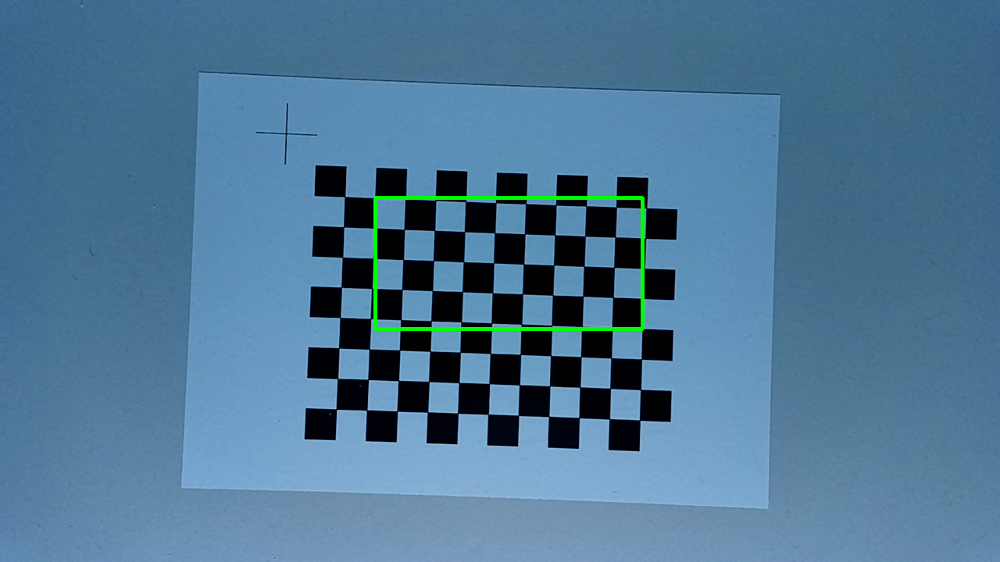

In [248]:
#To draw a rectangle, you need top left corner and bottom-right corner of rectangle. This time we will draw a green rectangle at the top right corner of image.
pt1 = (int(tlct[0]), int(tlct[1]))
pt2 = (int(brct[0]), int(brct[1]))
image_rect=image_BGR.copy()
superimposed=cv2.rectangle(image_rect, pt1, pt2, (0,255,0), 3)
cv2_imshow(superimposed)

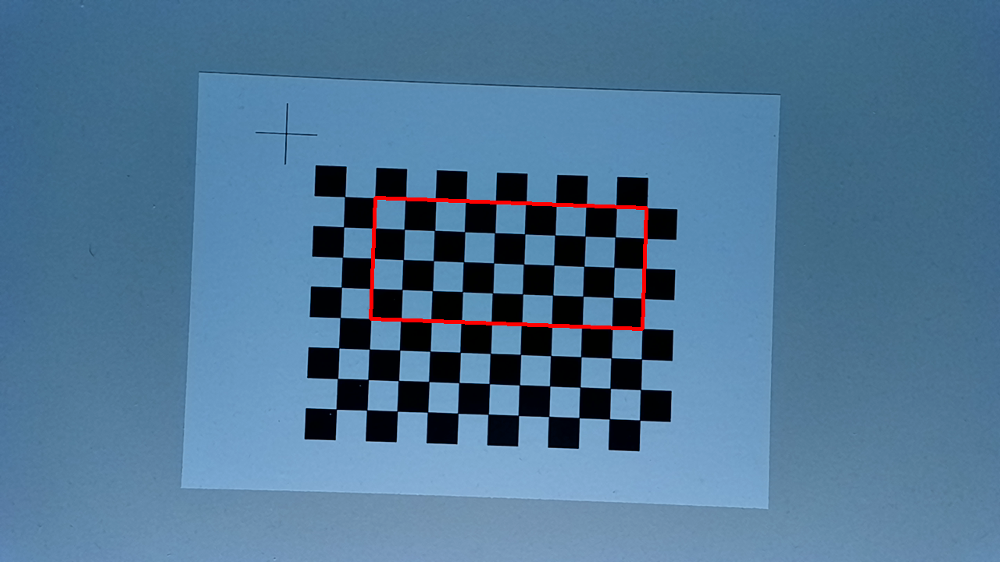

In [249]:
#better go with the line then
pt3=(int(p0_transformed[0]),int(p0_transformed[1]))
pt4 = (int(trct[0]), int(trct[1]))
image_line=image_BGR.copy()
superimposed_line= cv2.line(image_line,pt3,pt2,(0,0,255),4)
superimposed_line=cv2.line(superimposed_line,pt3,pt1,(0,0,255),4)
superimposed_line=cv2.line(superimposed_line,pt2,pt4,(0,0,255),4)
superimposed_line=cv2.line(superimposed_line,pt4,pt1,(0,0,255),4)

cv2_imshow(superimposed_line)

In [250]:
#Project
# first lets calculate num_tot_images homographies
#second we need to construct Vb=0
#third recover K from B
#lastly recover R and t

#first: we need corners for each image
import cv2
import numpy as np

# Initialize lists
drawn_images_par_find = []
all_found_corners = [] # List to store corners from each image

num_images = 0
num_tot_images = 25
# Assuming images_path and grid_size are defined previously
# example: grid_size = (11, 8)

for p in images_path:

    if num_images < num_tot_images:
        im = cv2.imread(p)

        # Check if image loaded successfully
        if im is None:
            continue

        img = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)

        return_value, corners_ = cv2.findChessboardCorners(img, patternSize=grid_size, corners=None)
        #print(corners)
        if return_value:
            all_found_corners.append(corners_)

            num_images += 1


#print(all_found_corners)

We have stacked the corners , now for each image lets calculte the homographies

In [251]:
homographies = []
grid_size_cv2 = tuple(reversed(grid_size))

# 2. Outer Loop: Iterate over each image found in all_found_corners
for i in range(len(all_found_corners)):
    img_corners = all_found_corners[i]
    corners = img_corners.reshape(-1, 2)
    #print(corners)
    # Initialize A for this specific image
    A=np.empty((0,9), dtype=float)
    A_first_point = np.empty((0, 9), dtype=float)
    A = A_first_point
    for i in range(len(corners)):
      u, v = corners[i][0], corners[i][1]

      #print(u,v)

      u_index, v_index = np.unravel_index(i, grid_size_cv2)
      #print(u_index,v_index)
      #the coordinates of the corner w.r.t. the reference corner at position (0,0) of the corners array
      x = (u_index) * square_size
      y = (v_index) * square_size

    # we store them in the real_coordinates array
      A_stack= np.array(
        [[x, y, 1, 0, 0, 0, -u * x, -u * y, -u],
        [0, 0, 0, x, y, 1, -v * x, -v * y, -v]
       ], dtype=np.float32)
      A=np.vstack([A, A_stack])



    # Now we solve A for the current image (still inside outer loop)

    U, S, Vh = np.linalg.svd(A, full_matrices=False)
    h = Vh[-1, :]   # last row of Vh (smallest singular value)
    H = h.reshape(3, 3)
    H=H/H[2,2]
    homographies.append(H)
    #print("Homography matrix H:")
print(homographies[1])


[[ 3.63174483e+00  1.73830105e-01  3.04873156e+01]
 [ 1.71350799e-01 -3.54042678e+00  5.24738815e+02]
 [ 1.02515123e-04  7.39449813e-05  1.00000000e+00]]


In [252]:
#second we need to construct Vb=0
#lets do it first for one homography

def get_v_ij(H, i, j):
    # Column i
    h_1i = H[0, i]
    h_2i = H[1, i]
    h_3i = H[2, i]

    # Column j
    h_1j = H[0, j]
    h_2j = H[1, j]
    h_3j = H[2, j]

    # Construct the vector components
    val1 = h_1i * h_1j
    val2 = h_1i * h_2j + h_2i * h_1j
    val3 = h_2i * h_2j
    val4 = h_3i * h_1j + h_1i * h_3j
    val5 = h_3i * h_2j + h_2i * h_3j
    val6 = h_3i * h_3j

    v_ij = np.array([val1, val2, val3, val4, val5, val6])

    return v_ij



def build_single_homography_constraints(H):

    v12 = get_v_ij(H, 0, 1)
    v11 = get_v_ij(H, 0, 0)
    v22 = get_v_ij(H, 1, 1)

    V_diff = v11 - v22
    V_diff=V_diff.T

    V_mat = np.vstack((v12.T, V_diff))

    return V_mat

def build_full_V_matrix(homographies):
    v_blocks = []


    for H in homographies:
        # Get the 2x6 block for the current H
        block = build_single_homography_constraints(H)
        v_blocks.append(block)

    # Stack all blocks vertically
    V = np.vstack(v_blocks)
    return V

V=build_full_V_matrix(homographies)
#print(V)

# check if i have to normalize





In [253]:
#Determing b
U, S, Vh = np.linalg.svd(V, full_matrices=False)
b=Vh[-1]

print(b)

#now we need to construct B
B=np.array([[b[0],b[1],b[3]],#first row
           [b[1],b[2],b[4]],
           [b[3],b[4],b[5]]])
#B=B+1e-04*np.identity(3)#adding an epsilon
if B[0,0]<0 or B[1,1]<0 or B[2,2]<0:
  B=B*-1
print(B)

L=np.linalg.cholesky(B, upper=False)
K=np.linalg.inv(L.T)
K=K/K[2,2]
K_geom=K
print(K)


[-6.30500938e-07  4.17058799e-10 -6.28178646e-07  3.95294672e-04
  2.34581943e-04 -9.99999894e-01]
[[ 6.30500938e-07 -4.17058799e-10 -3.95294672e-04]
 [-4.17058799e-10  6.28178646e-07 -2.34581943e-04]
 [-3.95294672e-04 -2.34581943e-04  9.99999894e-01]]
[[1.02650966e+03 6.80261625e-01 6.27200634e+02]
 [0.00000000e+00 1.02840557e+03 3.73848306e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]


In [254]:
#finding the pair R,t for each image

R_list = []
t_list = []

K_inv = np.linalg.inv(K)

for H in homographies:

  lam = 1 / np.linalg.norm(K_inv @ H[:, 0])

  r1 = lam * K_inv @ H[:, 0]
  r2 = lam * K_inv @ H[:, 1]

  r3 = np.cross(r1, r2)

  R = np.column_stack((r1, r2, r3))
  t = lam * K_inv @ H[:, 2]

  R_list.append(R)
  t_list.append(t)

R_closest=[]
for R in R_list:
  U, S, Vh = np.linalg.svd(R, full_matrices=False)
  R=U@Vh
  R_closest.append(R)
print("Closest in frobenius norm:",R_closest)
#print(R_closest[1])

Closest in frobenius norm: [array([[ 0.99929968,  0.03681634,  0.00668638],
       [ 0.03697682, -0.99898515, -0.02571725],
       [ 0.00573278,  0.02594648, -0.9996469 ]]), array([[ 0.99887673,  0.03648789,  0.03023103],
       [ 0.03710756, -0.99910716, -0.02019678],
       [ 0.0294671 ,  0.0212959 , -0.99933887]]), array([[ 0.99915952,  0.03522198,  0.02096804],
       [ 0.03568124, -0.99912219, -0.02194741],
       [ 0.02017661,  0.02267713, -0.99953922]]), array([[ 0.99929609,  0.03695614,  0.0064473 ],
       [ 0.03698228, -0.99930798, -0.0039837 ],
       [ 0.00629562,  0.00421934, -0.99997128]]), array([[ 0.99923496,  0.03864725, -0.00598989],
       [ 0.03846309, -0.99885927, -0.02829752],
       [-0.00707667,  0.02804548, -0.9995816 ]]), array([[ 0.99914802,  0.03710829, -0.01806125],
       [ 0.03668824, -0.99906072, -0.02305775],
       [-0.01889992,  0.02237547, -0.99957097]]), array([[ 0.99936349,  0.03523039, -0.00560727],
       [ 0.03513285, -0.9992442 , -0.01663468],


In [255]:
#POINT2: Total reprojection error and reprojected points
#choosing calibration image number ID
folderpath = GDrivePath + '/CVPR_project/images_and_poses_for_project_assignment/'
image_id = 16

filepath = folderpath + f'rgb_{image_id}.png'
image_BGR = cv2.imread(filepath)

image = cv2.cvtColor(image_BGR, cv2.COLOR_BGR2GRAY)

return_value, corners = cv2.findChessboardCorners(image, patternSize=grid_size)

fig = px.imshow(image, color_continuous_scale='gray')
fig.update_layout(coloraxis_showscale=False)
if return_value:
    corners_squeezed = corners.squeeze()

    x_coords = corners_squeezed[:, 0]
    y_coords = corners_squeezed[:, 1]

    fig.add_scatter(
        x=x_coords,
        y=y_coords,
        mode='markers',
        marker=dict(color='red', size=3),
        name='Corners'
    )

fig.show()

projected = np.empty((0, 3))
P = np.column_stack((K @ R_closest[image_id], K @ t_list[image_id]))

grid_size_cv2 = tuple(reversed(grid_size))

reprojection_error = 0
corners = corners.reshape(-1, 2)

for index, corner in enumerate(corners):
    u_index, v_index = np.unravel_index(index, grid_size_cv2)

    vector = np.array([(u_index) * square_size, (v_index) * square_size, 0, 1])
    vector = P @ vector
    vector = vector / vector[2]

    reprojection_error = reprojection_error + (vector[0] - corner[0])**2 + (vector[1] - corner[1])**2

    projected = np.vstack((projected, vector))

Output hidden; open in https://colab.research.google.com to view.

In [256]:
projected_x = projected[:, 0]
projected_y = projected[:, 1]

# add the projected points to the figure
fig.add_scatter(
    x=projected_x,
    y=projected_y,
    mode='markers',
    marker=dict(color='blue', size=3),
  name='Projected Points'
)

fig.show()

Output hidden; open in https://colab.research.google.com to view.

In [257]:
#lets calculate the reprojection error:
print("Total reprojection error:",reprojection_error)

Total reprojection error: 42.624164829209214


In [258]:
import plotly.express as px
import plotly.graph_objects as go


folderpath = GDrivePath + '/CVPR_project/images_and_poses_for_project_assignment/'
image_id =13
filepath = folderpath + f'rgb_{image_id}.png'

image_BGR = cv2.imread(filepath)
if image_BGR is None:
    raise FileNotFoundError(f"Could not load image at {filepath}")
image = cv2.cvtColor(image_BGR, cv2.COLOR_BGR2RGB)
return_value, corners = cv2.findChessboardCorners(image, patternSize=grid_size)

fig = px.imshow(image)

if return_value:
    # findchessboard corners displaying(red)
    corners_squeezed = corners.squeeze()


    # 2. projection for this image_id
    P = np.column_stack((K @ R_closest[image_id], K @ t_list[image_id]))
    grid_size_cv2 = tuple(reversed(grid_size))
    corners_flat = corners.reshape(-1, 2)
    projected_points = []

    for index, corner in enumerate(corners_flat):
        u_index, v_index = np.unravel_index(index, grid_size_cv2)
        x_world = u_index * square_size
        y_world = v_index * square_size

        world_point = np.array([x_world, y_world, 0, 1])

        proj_homog = P @ world_point
        proj_2d = proj_homog[:2] / proj_homog[2]
        projected_points.append(proj_2d)

    projected_points = np.array(projected_points)


    def get_cylinder_components(center_x, center_y, radius, height, P_matrix, segments=32):
        """
        generates 2D projected coordinates for the top surface,
        bottom surface, and connecting lines of a cylinder.
        """

        thetas = np.linspace(0, 2 * np.pi, segments)
        # Close the loop for filled polygons
        thetas_closed = np.append(thetas, thetas[0])

        z_bottom = 0
        z_top = height

       #Projection function
        def project_point(x, y, z):
            p_3d = np.array([x, y, z, 1])
            p_2d_homog = P_matrix @ p_3d
            return p_2d_homog[0] / p_2d_homog[2], p_2d_homog[1] / p_2d_homog[2]

        # 1. generate top and bottom Surface Vertices
        top_x, top_y = [], []
        bot_x, bot_y = [], []

        for theta in thetas_closed:
            wx = center_x + radius * np.cos(theta)
            wy = center_y + radius * np.sin(theta)

            tx, ty = project_point(wx, wy, z_top)
            bx, by = project_point(wx, wy, z_bottom)

            top_x.append(tx); top_y.append(ty)
            bot_x.append(bx); bot_y.append(by)

        # 2. Generate Vertical Struts (Wireframe)
        strut_x, strut_y = [], []
        # Use fewer segments for struts to avoid clutter
        strut_thetas = np.linspace(0, 2 * np.pi, 12, endpoint=False)
        for theta in strut_thetas:
            wx = center_x + radius * np.cos(theta)
            wy = center_y + radius * np.sin(theta)

            tx, ty = project_point(wx, wy, z_top)
            bx, by = project_point(wx, wy, z_bottom)

            # Add line segment followed by None to break the line
            strut_x.extend([bx, tx, None])
            strut_y.extend([by, ty, None])

        return (top_x, top_y), (bot_x, bot_y), (strut_x, strut_y)

    # Define Cylinder Properties
    cyl_center_x = 4 * square_size
    cyl_center_y = 5 * square_size
    cyl_radius = square_size * 3
    cyl_height = square_size * 8

    # Get components
    (top_X, top_Y), (bot_X, bot_Y), (struts_X, struts_Y) = get_cylinder_components(
        cyl_center_x, cyl_center_y, cyl_radius, cyl_height, P
    )


    #  bottom surface draw first so it's behind bottom surface
    fig.add_trace(go.Scatter(
        x=bot_X, y=bot_Y,
        fill='toself',
        fillcolor='rgba(0, 100, 0, 0.5)', # Dark green, semi-transparent
        line=dict(color='green', width=1),
        name='Cylinder Bottom'
    ))

    # 2. Vertical Struts
    fig.add_trace(go.Scatter(
        x=struts_X, y=struts_Y,
        mode='lines',
        line=dict(color='green', width=2),
        name='Cylinder Struts'
    ))

    # 3. Top Surface
    fig.add_trace(go.Scatter(
        x=top_X, y=top_Y,
        fill='toself',
        fillcolor='rgba(144, 238, 144, 0.7)', # light green more opaque
        line=dict(color='lightgreen', width=2),
        name='Cylinder Top'
    ))

fig.show()






In [259]:
import cv2
import numpy as np
import plotly.express as px
import sys

sys.path.append(GDrivePath +'CVPR_project/')
from utils import create_compound_image

def draw_cylinder_on_image(img, P_matrix, center_x, center_y, radius, height):
    """
    Draws a 3D cylinder on an image using a projection matrix P.
    """
    # Create a copy to draw on
    img_draw = img.copy()

    segments = 32
    thetas = np.linspace(0, 2 * np.pi, segments)
    z_bottom = 0
    z_top = height

    # Projection Helper
    def get_proj_point(x, y, z):
        p_3d = np.array([x, y, z, 1])
        p_2d_homog = P_matrix @ p_3d
        # Avoid division by zero
        if p_2d_homog[2] == 0: return (0,0)
        u = p_2d_homog[0] / p_2d_homog[2]
        v = p_2d_homog[1] / p_2d_homog[2]
        return (int(u), int(v))

    # Calculate vertices
    top_verts = []
    bot_verts = []

    for theta in thetas:
        wx = center_x + radius * np.cos(theta)
        wy = center_y + radius * np.sin(theta)
        top_verts.append(get_proj_point(wx, wy, z_top))
        bot_verts.append(get_proj_point(wx, wy, z_bottom))

    top_pts = np.array(top_verts, np.int32).reshape((-1, 1, 2))
    bot_pts = np.array(bot_verts, np.int32).reshape((-1, 1, 2))

    # bottom (Dark Green)
    cv2.fillPoly(img_draw, [bot_pts], (0, 100, 0))
    cv2.polylines(img_draw, [bot_pts], True, (0, 255, 0), 2)

    strut_indices = np.linspace(0, segments-1, 12, dtype=int)
    for i in strut_indices:
        pt_bot = bot_verts[i]
        pt_top = top_verts[i]
        cv2.line(img_draw, pt_bot, pt_top, (0, 150, 0), 2)

    overlay = img_draw.copy()
    cv2.fillPoly(overlay, [top_pts], (144, 238, 144))

    alpha = 0.6
    cv2.addWeighted(overlay, alpha, img_draw, 1 - alpha, 0, img_draw)
    cv2.polylines(img_draw, [top_pts], True, (144, 255, 144), 2)

    return img_draw


folderpath = GDrivePath + '/CVPR_project/images_and_poses_for_project_assignment/'
drawn_images = []

# Cylinder World Definition
cyl_center_x = 4 * square_size
cyl_center_y = 5 * square_size
cyl_radius = square_size * 3
cyl_height = square_size * 5


total_images = 5 * 5 # 20 images

print("Processing images (Converting to Gray -> Projecting)...")

for i in range(total_images):
    filepath = folderpath + f'rgb_{i}.png'

    image_BGR = cv2.imread(filepath)
    if image_BGR is None:
        drawn_images.append(np.zeros((480, 640, 3), dtype=np.uint8))
        continue

    #  Convert to Grayscale
    image_gray = cv2.cvtColor(image_BGR, cv2.COLOR_BGR2GRAY)

    # (We need 3 channels to draw the GREEN cylinder, otherwise the cylinder would be gray too)
    image_gray_rgb = cv2.cvtColor(image_gray, cv2.COLOR_GRAY2RGB)

    # Calculate Projection Matrix P
    P = np.column_stack((K @ R_closest[i], K @ t_list[i]))

    processed_image = draw_cylinder_on_image(
        image_gray_rgb,
        P,
        cyl_center_x,
        cyl_center_y,
        cyl_radius,
        cyl_height
    )

    drawn_images.append(processed_image)


compound_image = create_compound_image(rows=5, cols=5, limages=drawn_images)

fig = px.imshow(compound_image, width=1200, height=800)
fig.update_layout(title="Projected Cylinders ")
fig.show()

Output hidden; open in https://colab.research.google.com to view.

In [260]:
#starting from the previous we will minimize using  Levenberg–Marquardt algorithm the non linear minimization problem
#NOW JUST FOR 1 IMAGE, indeed results no sense


import numpy as np
import cv2
from scipy.optimize import least_squares


image_id = 16
corners = all_found_corners[image_id]
img_points = corners.reshape(-1, 2)

obj_points = []
for index in range(len(img_points)):
    u_index, v_index = np.unravel_index(index, grid_size_cv2)
    obj_points.append([u_index * square_size, v_index * square_size, 0])

obj_points = np.array(obj_points, dtype=np.float32)


initial_R = R_closest[image_id]
initial_t = t_list[image_id]
initial_K = K_geom

r_vec_initial, _ = cv2.Rodrigues(initial_R)

# K iS [[fx, 0, cx], [0, fy, cy], [0, 0, 1]]
k_params = [initial_K[0,0], initial_K[1,1], initial_K[0,2], initial_K[1,2]]

# Combine ALL into one flat array for optimizer
# [fx, fy, cx, cy, rx, ry, rz, tx, ty, tz] (10 parameters)
x0 = np.concatenate((k_params, r_vec_initial.flatten(), initial_t.flatten()))

def rodrigues_vec_to_mat(r_vec):
    """Helper to convert rotation vector to matrix manually"""
    theta = np.linalg.norm(r_vec)
    if theta < 1e-6: return np.eye(3)
    u = r_vec / theta
    K_skew = np.array([[0, -u[2], u[1]], [u[2], 0, -u[0]], [-u[1], u[0], 0]])
    return np.eye(3) + np.sin(theta) * K_skew + (1 - np.cos(theta)) * (K_skew @ K_skew)

def reprojection_residuals(params, obj_points, observed_points):
    """
    params: 10 elements [fx, fy, cx, cy, rx, ry, rz, tx, ty, tz]
    """
    fx, fy, cx, cy = params[0:4]

    r_vec = params[4:7]
    t_vec = params[7:10]


    K_curr = np.array([
        [fx, 0,  cx],
        [0,  fy, cy],
        [0,  0,  1 ]
    ])

    R_curr = rodrigues_vec_to_mat(r_vec)
    t_curr = t_vec.reshape(3, 1)

    extrinsic = np.column_stack((R_curr, t_curr))
    P = K_curr @ extrinsic


    num_points = obj_points.shape[0]
    ones = np.ones((num_points, 1))
    points_hom = np.hstack((obj_points, ones))

    # Project
    projected_hom = (P @ points_hom.T).T

    z = projected_hom[:, 2]
    u = projected_hom[:, 0] / (z + 1e-10)
    v = projected_hom[:, 1] / (z + 1e-10)

    projected_points_2d = np.column_stack((u, v))

    return (projected_points_2d - observed_points).flatten()

# Run Optimization


result = least_squares(
    reprojection_residuals,
    x0=x0,
    method='lm',
    args=(obj_points, img_points), # Pass constants here
    verbose=1
)


opt_params = result.x

fx_opt, fy_opt, cx_opt, cy_opt = opt_params[0:4]
K_opt = np.array([
    [fx_opt, 0,      cx_opt],
    [0,      fy_opt, cy_opt],
    [0,      0,      1     ]
])

# B. Extract R and t
opt_r_vec = opt_params[4:7]
opt_t_vec = opt_params[7:10]

R_opt = rodrigues_vec_to_mat(opt_r_vec)
t_opt = opt_t_vec.reshape(3, 1)

# C. Calculate Errors
final_residuals = reprojection_residuals(opt_params, obj_points, img_points)
final_error_sum = np.sum(final_residuals**2)
mean_error = np.mean(final_residuals**2)


print("\n" + "="*30)
print(f"Optimization Success: {result.success}")
print(f"Total Sum of Squared Error: {final_error_sum:.4f}")
print(f"Mean Squared Error: {mean_error:.4f}")
print("="*30)

print("\nOptimized K Matrix:")
print(K_opt)

print("\nOptimized Rotation Matrix (R):")
print(R_opt)

print("\nOptimized Translation Vector (t):")
print(t_opt)



`ftol` termination condition is satisfied.
Function evaluations 16, initial cost 2.1274e+01, final cost 2.4258e+00, first-order optimality 1.81e-02.

Optimization Success: True
Total Sum of Squared Error: 4.8516
Mean Squared Error: 0.0276

Optimized K Matrix:
[[836.17806622   0.         651.06591642]
 [  0.         846.22472495 302.1516167 ]
 [  0.           0.           1.        ]]

Optimized Rotation Matrix (R):
[[ 0.99232911  0.04085648 -0.1166777 ]
 [ 0.05417706 -0.99207357  0.11337937]
 [-0.11112058 -0.1188309  -0.98667697]]

Optimized Translation Vector (t):
[[-106.16753747]
 [  75.07243056]
 [ 259.74547271]]


In [261]:
print("\nInitial K Matrix:")
print(initial_K)

print("\nInitial Rotation Matrix (R):")
print(initial_R)

print("\nInitial Translation Vector (t):")
print(initial_t)



Initial K Matrix:
[[1.02650966e+03 6.80261625e-01 6.27200634e+02]
 [0.00000000e+00 1.02840557e+03 3.73848306e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]

Initial Rotation Matrix (R):
[[ 0.98870224  0.04099223 -0.14417877]
 [ 0.06119457 -0.98845498  0.1386073 ]
 [-0.1368324  -0.14586431 -0.97979615]]

Initial Translation Vector (t):
[-98.73567996  53.57543423 318.69958044]


In [262]:
#Lets plot the optimized

folderpath = GDrivePath + '/CVPR_project/images_and_poses_for_project_assignment/'
image_id = 16

filepath = folderpath + f'rgb_{image_id}.png'
image_BGR = cv2.imread(filepath)

image = cv2.cvtColor(image_BGR, cv2.COLOR_BGR2GRAY)

return_value, corners = cv2.findChessboardCorners(image, patternSize=grid_size)

fig = px.imshow(image, color_continuous_scale='gray')
fig.update_layout(coloraxis_showscale=False)
if return_value:
    corners_squeezed = corners.squeeze()

    x_coords = corners_squeezed[:, 0]
    y_coords = corners_squeezed[:, 1]

    fig.add_scatter(
        x=x_coords,
        y=y_coords,
        mode='markers',
        marker=dict(color='red', size=3),
        name='Corners'
    )

fig.show()

projected = np.empty((0, 3))
P = np.column_stack((K_opt @ R_opt, K @ t_opt))

grid_size_cv2 = tuple(reversed(grid_size))

reprojection_error = 0
corners = corners.reshape(-1, 2)

for index, corner in enumerate(corners):
    u_index, v_index = np.unravel_index(index, grid_size_cv2)

    vector = np.array([(u_index) * square_size, (v_index) * square_size, 0, 1])
    vector = P @ vector
    vector = vector / vector[2]


    projected = np.vstack((projected, vector))


Output hidden; open in https://colab.research.google.com to view.

In [263]:
projected_x = projected[:, 0]
projected_y = projected[:, 1]

# add the projected points to the figure
fig.add_scatter(
    x=projected_x,
    y=projected_y,
    mode='markers',
    marker=dict(color='blue', size=3),
  name='Projected Points'
)

fig.show()

Output hidden; open in https://colab.research.google.com to view.

In [264]:
import numpy as np
import cv2
from scipy.optimize import least_squares
#now we consider not only an image but 25 of them!

def rodrigues_vec_to_mat(r_vec):
    theta = np.linalg.norm(r_vec)
    if theta < 1e-6: return np.eye(3)
    u = r_vec / theta
    K_skew = np.array([[0, -u[2], u[1]], [u[2], 0, -u[0]], [-u[1], u[0], 0]])
    return np.eye(3) + np.sin(theta) * K_skew + (1 - np.cos(theta)) * (K_skew @ K_skew)


# We need to stack ALL parameters into one huge list:
# Structure: [fx, fy, cx, cy,  rx0, ry0, rz0, tx0, ty0, tz0,  rx1, ... ]

# Initialize Shared Intrinsic Parameters (K)
# K is [[fx, 0, cx], [0, fy, cy], [0, 0, 1]]
k_params = [K_geom[0,0], K_geom[1,1], K_geom[0,2], K_geom[1,2]]

# Initialize Per-Image Pose Parameters
pose_params = []
valid_image_indices = [] # Keep track of which images we are actually using
all_obj_points = []      # List of 3D point arrays
all_img_points = []      # List of 2D corner arrays

print("Collecting data from images...")

# Iterate over all potential images
for i in range(len(all_found_corners)):
    corners = all_found_corners[i]

    # Skip images where no corners were found
    if corners is None or len(corners) == 0:
        continue

    valid_image_indices.append(i)

    # store observed 2D Points
    img_pts = corners.reshape(-1, 2)
    all_img_points.append(img_pts)

    # 2. Generate 3D Object Points (Same grid for every image)
    obj_pts = []
    for index in range(len(img_pts)):
        u_index, v_index = np.unravel_index(index, grid_size_cv2)
        obj_pts.append([u_index * square_size, v_index * square_size, 0])
    all_obj_points.append(np.array(obj_pts, dtype=np.float32))

    # Get Initial Pose Guess (R, t) from your previous lists
    curr_R = R_closest[i]
    curr_t = t_list[i]

    # Convert R matrix to Vector
    r_vec, _ = cv2.Rodrigues(curr_R)

    # Append to params list: [rx, ry, rz, tx, ty, tz]
    pose_params.extend(r_vec.flatten())
    pose_params.extend(curr_t.flatten())

# Combine K and All Poses into one state vector 'x0'
x0 = np.concatenate((k_params, pose_params))
print(f"Total Parameters to Optimize: {len(x0)}")
print(f"Number of Valid Images: {len(valid_image_indices)}")



def bundle_adjustment_residuals(params, all_obj_points, all_img_points):
    """
    params structure:
    [0:4]   -> K (fx, fy, cx, cy)
    [4:10]  -> Pose Image 0 (r_vec, t_vec)
    [10:16] -> Pose Image 1 and so on
    ...
    """
    #reconstruct K (
    fx, fy, cx, cy = params[0:4]
    K_curr = np.array([
        [fx, 0,  cx],
        [0,  fy, cy],
        [0,  0,  1 ]
    ])

    all_residuals = []

    #  Loop through every image
    num_images = len(all_obj_points)

    for i in range(num_images):
        # 1. Extract Pose for this image
        start_idx = 4 + (i * 6)
        end_idx = start_idx + 6
        pose_data = params[start_idx:end_idx]

        r_vec = pose_data[:3]
        t_vec = pose_data[3:]

        # 2. Build P Matrix
        R_curr = rodrigues_vec_to_mat(r_vec)
        t_curr = t_vec.reshape(3, 1)

        extrinsic = np.column_stack((R_curr, t_curr))
        P = K_curr @ extrinsic

        # 3. Project Points
        obj_pts = all_obj_points[i]
        observed_pts = all_img_points[i]

        # Homogeneous Coords (N, 4)
        ones = np.ones((obj_pts.shape[0], 1))
        pts_hom = np.hstack((obj_pts, ones))

        proj_hom = (P @ pts_hom.T).T

        # Perspective Division
        z = proj_hom[:, 2]
        u = proj_hom[:, 0] / (z + 1e-10)
        v = proj_hom[:, 1] / (z + 1e-10)

        proj_2d = np.column_stack((u, v))

        # 4. Calculate Errors and Append
        # Flattening ensures we get a 1D array of all errors for this image
        diff = (proj_2d - observed_pts).flatten()
        all_residuals.append(diff)

    # Concatenate residuals from ALL images into one massive array
    return np.concatenate(all_residuals)

#Optimization

print("Starting Bundle Adjustment (This may take a moment)...")

#  use 'jac' scaling to balance small rotation angles vs large translation units
result = least_squares(
    bundle_adjustment_residuals,
    x0=x0,
    method='lm',
    x_scale='jac',
    args=(all_obj_points, all_img_points),
    verbose=1
)


final_params = result.x

#Extract Optimized K
fx_opt, fy_opt, cx_opt, cy_opt = final_params[0:4]
K_optimized = np.array([
    [fx_opt, 0,      cx_opt],
    [0,      fy_opt, cy_opt],
    [0,      0,      1     ]
])

print("\n" + "="*30)
print("Optimization Complete")
print("="*30)
print("Optimized K Matrix:")
print(K_optimized)

#  Poses for all images
R_closest2=R_closest
t_list2=t_list
for i, original_idx in enumerate(valid_image_indices):
    start_idx = 4 + (i * 6)
    pose_data = final_params[start_idx : start_idx + 6]

    r_vec_opt = pose_data[:3]
    t_vec_opt = pose_data[3:].reshape(3, 1)

    R_opt = rodrigues_vec_to_mat(r_vec_opt)

    # Update original data structures
    R_closest[original_idx] = R_opt
    t_list[original_idx] = t_vec_opt

# Calculate Final Total Error
final_res = bundle_adjustment_residuals(final_params, all_obj_points, all_img_points)
mean_error = np.mean(final_res**2)
print(f"\nFinal Mean Squared Error per pixel coordinate: {mean_error:.5f}")

# Update the global K variable for future use
K = K_optimized

Total Parameters to Optimize: 154
Number of Valid Images: 25
Starting Bundle Adjustment (This may take a moment)...
`ftol` termination condition is satisfied.
Function evaluations 5, initial cost 5.6539e+02, final cost 1.4460e+02, first-order optimality 2.24e-04.

Optimization Complete
Optimized K Matrix:
[[1.02597745e+03 0.00000000e+00 6.27526159e+02]
 [0.00000000e+00 1.02788806e+03 3.73673429e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]

Final Mean Squared Error per pixel coordinate: 0.06573


In [265]:
#POINT2: Total reprojection error and reprojected points
#choosing calibration image number ID
folderpath = GDrivePath + '/CVPR_project/images_and_poses_for_project_assignment/'
image_id = 16

filepath = folderpath + f'rgb_{image_id}.png'
image_BGR = cv2.imread(filepath)

image = cv2.cvtColor(image_BGR, cv2.COLOR_BGR2GRAY)

return_value, corners = cv2.findChessboardCorners(image, patternSize=grid_size)

fig = px.imshow(image, color_continuous_scale='gray')
fig.update_layout(coloraxis_showscale=False)
if return_value:
    corners_squeezed = corners.squeeze()

    x_coords = corners_squeezed[:, 0]
    y_coords = corners_squeezed[:, 1]

    fig.add_scatter(
        x=x_coords,
        y=y_coords,
        mode='markers',
        marker=dict(color='red', size=3),
        name='Corners'
    )

fig.show()

projected = np.empty((0, 3))
P = np.column_stack((K @ R_closest[image_id], K @ t_list[image_id]))

grid_size_cv2 = tuple(reversed(grid_size))

reprojection_error = 0
corners = corners.reshape(-1, 2)

for index, corner in enumerate(corners):
    u_index, v_index = np.unravel_index(index, grid_size_cv2)

    vector = np.array([(u_index) * square_size, (v_index) * square_size, 0, 1])
    vector = P @ vector
    vector = vector / vector[2]

    reprojection_error = reprojection_error + (vector[0] - corner[0])**2 + (vector[1] - corner[1])**2

    projected = np.vstack((projected, vector))

Output hidden; open in https://colab.research.google.com to view.

In [266]:
projected_x = projected[:, 0]
projected_y = projected[:, 1]

# add the projected points to the figure
fig.add_scatter(
    x=projected_x,
    y=projected_y,
    mode='markers',
    marker=dict(color='blue', size=3),
  name='Projected Points'
)

fig.show()

Output hidden; open in https://colab.research.google.com to view.

In [267]:
print(reprojection_error)
print(x0.shape)

10.3352864472518
(154,)


In [268]:
#now lets use the model of K with the skew angle also
import numpy as np
import cv2
from scipy.optimize import least_squares

def rodrigues_vec_to_mat(r_vec):
    theta = np.linalg.norm(r_vec)
    if theta < 1e-6: return np.eye(3)
    u = r_vec / theta
    K_skew = np.array([[0, -u[2], u[1]], [u[2], 0, -u[0]], [-u[1], u[0], 0]])
    return np.eye(3) + np.sin(theta) * K_skew + (1 - np.cos(theta)) * (K_skew @ K_skew)


# We need to stack ALL parameters into one huge list:
# atructure: [fx, fy, fxcot, cx, cy,  rx0, ry0, rz0, tx0, ty0, tz0,  rx1, ... ]

# Initialize Shared Intrinsic Parameters (K)
# K is [[fx, 0, cx], [0, fy, cy], [0, 0, 1]]
print(K_geom)
k_params = [K_geom[0,0], K_geom[1,1], K_geom[0,1], K_geom[0,2], K_geom[1,2]]

# Initialize PerImage Pose Parameters
pose_params = []
valid_image_indices = [] #kKeep track of which images we are actually using
all_obj_points = []      # list of 3D point arrays
all_img_points = []      # list of 2D corner arrays

print("Collecting data from images...")

# Iterate over all potential images
for i in range(len(all_found_corners)):
    corners = all_found_corners[i]

    # Skip images where no corners were found
    if corners is None or len(corners) == 0:
        continue

    valid_image_indices.append(i)

    # store observed 2D Points
    img_pts = corners.reshape(-1, 2)
    all_img_points.append(img_pts)

    # 2. Generate 3D Object Points (Same grid for every image)
    obj_pts = []
    for index in range(len(img_pts)):
        u_index, v_index = np.unravel_index(index, grid_size_cv2)
        obj_pts.append([u_index * square_size, v_index * square_size, 0])
    all_obj_points.append(np.array(obj_pts, dtype=np.float32))

    # Get Initial Pose Guess (R, t) from your previous lists
    curr_R = R_closest2[i]
    curr_t = t_list2[i]

    # Convert R matrix to Vector
    r_vec, _ = cv2.Rodrigues(curr_R)

    # Append to params list: [rx, ry, rz, tx, ty, tz]
    pose_params.extend(r_vec.flatten())
    pose_params.extend(curr_t.flatten())

# Combine K and All Poses into one state vector 'x0'
x0 = np.concatenate((k_params, pose_params))
print(f"Total Parameters to Optimize: {len(x0)}")
print(f"Number of Valid Images: {len(valid_image_indices)}")



def bundle_adjustment_residuals(params, all_obj_points, all_img_points):
    """
    params structure:
    [0:4]   -> K (fx, fy, cx, cy)
    [4:10]  -> Pose Image 0 (r_vec, t_vec)
    [10:16] -> Pose Image 1 and so on
    ...
    """
    #reconstruct K (
    fx, fy, fxcot, cx, cy = params[0:5]
    K_curr = np.array([
        [fx, fxcot,  cx],
        [0,  fy, cy],
        [0,  0,  1 ]
    ])

    all_residuals = []

    #  Loop through every image
    num_images = len(all_obj_points)

    for i in range(num_images):
        # 1. Extract Pose for this image
        start_idx = 5 + (i * 6)
        end_idx = start_idx + 6
        pose_data = params[start_idx:end_idx]

        r_vec = pose_data[:3]
        t_vec = pose_data[3:]

        # 2. Build P Matrix
        R_curr = rodrigues_vec_to_mat(r_vec)
        t_curr = t_vec.reshape(3, 1)

        extrinsic = np.column_stack((R_curr, t_curr))
        P = K_curr @ extrinsic

        # 3. Project Points
        obj_pts = all_obj_points[i]
        observed_pts = all_img_points[i]

        # Homogeneous Coords (N, 4)
        ones = np.ones((obj_pts.shape[0], 1))
        pts_hom = np.hstack((obj_pts, ones))

        proj_hom = (P @ pts_hom.T).T

        # Perspective Division
        z = proj_hom[:, 2]
        u = proj_hom[:, 0] / (z + 1e-10)
        v = proj_hom[:, 1] / (z + 1e-10)

        proj_2d = np.column_stack((u, v))

        # 4. Calculate Errors and Append
        # Flattening ensures we get a 1D array of all errors for this image
        diff = (proj_2d - observed_pts).flatten()
        all_residuals.append(diff)

    # Concatenate residuals from ALL images into one massive array
    return np.concatenate(all_residuals)

#Optimization

print("Starting Bundle Adjustment (This may take a moment)...")

#  use 'jac' scaling to balance small rotation angles vs large translation units
result = least_squares(
    bundle_adjustment_residuals,
    x0=x0,
    method='lm',
    x_scale='jac',
    args=(all_obj_points, all_img_points),
    verbose=1
)


final_params = result.x

#Extract Optimized K
fx_opt, fy_opt, fxcot_opt, cx_opt, cy_opt = final_params[0:5]
K_optimized = np.array([
    [fx_opt, fxcot_opt,      cx_opt],
    [0,      fy_opt, cy_opt],
    [0,      0,      1     ]
])

print("\n" + "="*30)
print("Optimization Complete")
print("="*30)
print("Optimized K Matrix:")
print(K_optimized)

#  Poses for all images
R_closest2=R_closest
t_list2=t_list
for i, original_idx in enumerate(valid_image_indices):
    start_idx = 5 + (i * 6)
    pose_data = final_params[start_idx : start_idx + 6]

    r_vec_opt = pose_data[:3]
    t_vec_opt = pose_data[3:].reshape(3, 1)

    R_opt = rodrigues_vec_to_mat(r_vec_opt)

    # Update original data structures
    R_closest[original_idx] = R_opt
    t_list[original_idx] = t_vec_opt

# Calculate Final Total Error
final_res = bundle_adjustment_residuals(final_params, all_obj_points, all_img_points)
mean_error = np.mean(final_res**2)
print(f"\nFinal Mean Squared Error per pixel coordinate: {mean_error:.5f}")

# Update the global K variable for future use
K = K_optimized

[[1.02650966e+03 6.80261625e-01 6.27200634e+02]
 [0.00000000e+00 1.02840557e+03 3.73848306e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
Total Parameters to Optimize: 155
Number of Valid Images: 25
Starting Bundle Adjustment (This may take a moment)...
`ftol` termination condition is satisfied.
Function evaluations 4, initial cost 3.1371e+02, final cost 1.4351e+02, first-order optimality 6.17e-04.

Optimization Complete
Optimized K Matrix:
[[1.02609332e+03 8.41746244e-01 6.27731566e+02]
 [0.00000000e+00 1.02800305e+03 3.73581766e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]

Final Mean Squared Error per pixel coordinate: 0.06523


In [269]:
#POINT2: Total reprojection error and reprojected points
#choosing calibration image number ID
folderpath = GDrivePath + '/CVPR_project/images_and_poses_for_project_assignment/'
image_id = 16

filepath = folderpath + f'rgb_{image_id}.png'
image_BGR = cv2.imread(filepath)

image = cv2.cvtColor(image_BGR, cv2.COLOR_BGR2GRAY)

return_value, corners = cv2.findChessboardCorners(image, patternSize=grid_size)

fig = px.imshow(image, color_continuous_scale='gray')
fig.update_layout(coloraxis_showscale=False)
if return_value:
    corners_squeezed = corners.squeeze()

    x_coords = corners_squeezed[:, 0]
    y_coords = corners_squeezed[:, 1]

    fig.add_scatter(
        x=x_coords,
        y=y_coords,
        mode='markers',
        marker=dict(color='red', size=3),
        name='Corners'
    )

fig.show()

projected = np.empty((0, 3))
P = np.column_stack((K @ R_closest[image_id], K @ t_list[image_id]))

grid_size_cv2 = tuple(reversed(grid_size))

reprojection_error = 0
corners = corners.reshape(-1, 2)

for index, corner in enumerate(corners):
    u_index, v_index = np.unravel_index(index, grid_size_cv2)

    vector = np.array([(u_index) * square_size, (v_index) * square_size, 0, 1])
    vector = P @ vector
    vector = vector / vector[2]

    reprojection_error = reprojection_error + (vector[0] - corner[0])**2 + (vector[1] - corner[1])**2

    projected = np.vstack((projected, vector))

Output hidden; open in https://colab.research.google.com to view.

In [270]:
projected_x = projected[:, 0]
projected_y = projected[:, 1]

# add the projected points to the figure
fig.add_scatter(
    x=projected_x,
    y=projected_y,
    mode='markers',
    marker=dict(color='blue', size=3),
  name='Projected Points'
)

fig.show()

Output hidden; open in https://colab.research.google.com to view.

In [271]:
print(reprojection_error)
print(x0.shape)

9.359167309267976
(155,)


Precomputing homographies for 25 images...
Homographies computed.
Starting Experiment (N=3 to 25)...
N=3: std_u=43.68, std_v=49.90 (from 46 trials)
N=4: std_u=17.21, std_v=12.24 (from 50 trials)
N=5: std_u=14.20, std_v=12.98 (from 49 trials)
N=6: std_u=12.98, std_v=11.65 (from 50 trials)
N=7: std_u=8.41, std_v=11.43 (from 50 trials)
N=8: std_u=5.02, std_v=8.90 (from 50 trials)
N=9: std_u=4.24, std_v=3.53 (from 50 trials)
N=10: std_u=5.80, std_v=3.31 (from 50 trials)
N=11: std_u=4.83, std_v=2.96 (from 50 trials)
N=12: std_u=4.86, std_v=3.03 (from 50 trials)
N=13: std_u=3.16, std_v=1.88 (from 50 trials)
N=14: std_u=2.52, std_v=1.69 (from 50 trials)
N=15: std_u=3.27, std_v=1.67 (from 50 trials)
N=16: std_u=2.60, std_v=1.31 (from 50 trials)
N=17: std_u=2.19, std_v=1.17 (from 50 trials)
N=18: std_u=1.70, std_v=0.87 (from 50 trials)
N=19: std_u=1.72, std_v=0.89 (from 50 trials)
N=20: std_u=1.52, std_v=0.90 (from 50 trials)
N=21: std_u=1.57, std_v=0.68 (from 50 trials)
N=22: std_u=1.09, std_v

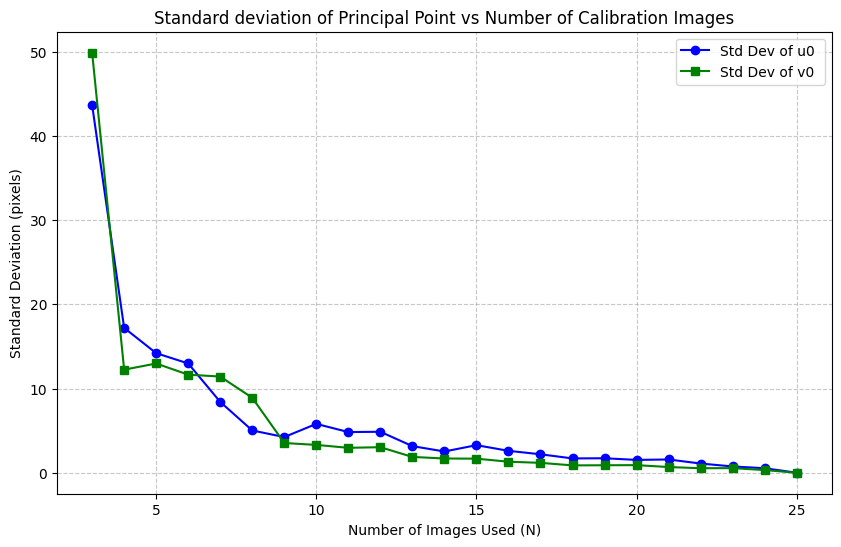

In [272]:
#Analize the standard deviation of the principal point as a function of the number of images
#used for calibration.
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random


num_tot_images = 25
all_found_corners = []
valid_images_indices = []

num_images = 0
for idx, p in enumerate(images_path):
    if num_images >= num_tot_images:
        break

    im = cv2.imread(p)
    if im is None: continue

    img = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    return_value, corners_ = cv2.findChessboardCorners(img, patternSize=grid_size, corners=None)

    if return_value:
        all_found_corners.append(corners_)
        valid_images_indices.append(idx)
        num_images += 1

grid_size_cv2 = tuple(reversed(grid_size))


print(f"Precomputing homographies for {len(all_found_corners)} images...")
all_homographies = []

for i in range(len(all_found_corners)):
    img_corners = all_found_corners[i]
    corners = img_corners.reshape(-1, 2)

    # Initialize A for this specific image
    A = np.empty((0, 9), dtype=float)

    # Build A matrix for DLT
    for j in range(len(corners)):
        u, v = corners[j][0], corners[j][1]
        u_index, v_index = np.unravel_index(j, grid_size_cv2)

        x = u_index * square_size
        y = v_index * square_size

        A_stack = np.array([
            [x, y, 1, 0, 0, 0, -u * x, -u * y, -u],
            [0, 0, 0, x, y, 1, -v * x, -v * y, -v]
        ], dtype=np.float32)
        A = np.vstack([A, A_stack])

    # Solve A using SVD
    U, S, Vh = np.linalg.svd(A, full_matrices=False)
    h = Vh[-1, :]
    H = h.reshape(3, 3)
    H = H / H[2, 2] # Normalize
    all_homographies.append(H)

print("Homographies computed.")

def get_v_ij(H, i, j):
    h_1i, h_2i, h_3i = H[0, i], H[1, i], H[2, i]
    h_1j, h_2j, h_3j = H[0, j], H[1, j], H[2, j]

    val1 = h_1i * h_1j
    val2 = h_1i * h_2j + h_2i * h_1j
    val3 = h_2i * h_2j
    val4 = h_3i * h_1j + h_1i * h_3j
    val5 = h_3i * h_2j + h_2i * h_3j
    val6 = h_3i * h_3j

    return np.array([val1, val2, val3, val4, val5, val6])

def build_V_matrix(homographies_subset):
    v_blocks = []
    for H in homographies_subset:
        v12 = get_v_ij(H, 0, 1)
        v11 = get_v_ij(H, 0, 0)
        v22 = get_v_ij(H, 1, 1)

        V_diff = (v11 - v22).T
        V_mat = np.vstack((v12.T, V_diff))
        v_blocks.append(V_mat)

    return np.vstack(v_blocks)

def estimate_K_from_homographies(homographies_subset):
    # 1. Build V
    V = build_V_matrix(homographies_subset)

    # 2. Solve Vb = 0
    U, S, Vh = np.linalg.svd(V, full_matrices=False)
    b = Vh[-1]

    # 3. Construct B
    B = np.array([
        [b[0], b[1], b[3]],
        [b[1], b[2], b[4]],
        [b[3], b[4], b[5]]
    ])

    if B[0, 0] < 0 or B[1, 1] < 0 or B[2, 2] < 0:
        B = -B


    try:
        L = np.linalg.cholesky(B)
    except np.linalg.LinAlgError:
        return None # Failed to find a valid K


    # L comes from B = L L^T.
    K_est = np.linalg.inv(L.T)
    K_est = K_est / K_est[2, 2]

    return K_est

#n the following experiment we consider the first 25 images as before, for each subset going
#from 3 to 25 we select the a random number of images of the length
#of the current subset and calculate the standard deviation of
#the entries u0,v0 for that specific subset,for a total of 50 trials
#for each subset

min_images = 3
max_images = len(all_homographies)
trials_per_n = 50  # How many random subsets to test per N

u0_stds = []
v0_stds = []
n_values = range(min_images, max_images + 1)

print(f"Starting Experiment (N={min_images} to {max_images})...")

for n in n_values:
    u0_samples = []
    v0_samples = []

    valid_trials = 0

    for _ in range(trials_per_n):
        # randomly select 'n' homographies
        subset_H = random.sample(all_homographies, n)

        K_res = estimate_K_from_homographies(subset_H)

        if K_res is not None:
            # extract principal point
            u0 = K_res[0, 2]
            v0 = K_res[1, 2]

            if 0 < u0 < 5000 and 0 < v0 < 5000:
                u0_samples.append(u0)
                v0_samples.append(v0)
                valid_trials += 1

    # calculate Standard Deviation for this N
    if valid_trials > 1:
        std_u = np.std(u0_samples)
        std_v = np.std(v0_samples)
        u0_stds.append(std_u)
        v0_stds.append(std_v)
        print(f"N={n}: std_u={std_u:.2f}, std_v={std_v:.2f} (from {valid_trials} trials)")
    else:
        u0_stds.append(0)
        v0_stds.append(0)
        print(f"N={n}: Not enough valid solutions found.")



plt.figure(figsize=(10, 6))
plt.plot(n_values, u0_stds, marker='o', label='Std Dev of u0 ', color='blue')
plt.plot(n_values, v0_stds, marker='s', label='Std Dev of v0 ', color='green')

plt.title('Standard deviation of Principal Point vs Number of Calibration Images')
plt.xlabel('Number of Images Used (N)')
plt.ylabel('Standard Deviation (pixels)')
plt.grid(True, which='both', linestyle='--', alpha=0.7)
plt.legend()
plt.show()


In [273]:
print(len(all_homographies))

25
